<a href="https://colab.research.google.com/github/omrani-wiem/look_alike/blob/main/look_alike.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q datasets transformers faiss-cpu
from datasets import load_dataset
ds = load_dataset("drag88/snitch_image_binary_with_proddesc", split="train")
print(ds)
print(ds.column_names)
df = ds.remove_columns([c for c in ds.column_names if 'image' in c.lower()]).to_pandas()
print(df.head())
print(df['Price'].describe())

README.md:   0%|          | 0.00/688 [00:00<?, ?B/s]

data/train-00000-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  338MB            

data/train-00000-of-00004.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  303MB            

data/train-00001-of-00004.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  333MB            

data/train-00002-of-00004.parquet: downloading bytes:           |  0.00B            

data/train-00003-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  361MB            

data/train-00003-of-00004.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8832 [00:00<?, ? examples/s]

Dataset({
    features: ['Price', 'Product Description', 'Product ID', 'Product Name', 'Store', 'Tags', 'Vendor', 'Size', 'Product Image Link', 'image_bytes', 'enhanced_description'],
    num_rows: 8832
})
['Price', 'Product Description', 'Product ID', 'Product Name', 'Store', 'Tags', 'Vendor', 'Size', 'Product Image Link', 'image_bytes', 'enhanced_description']
    Price                                Product Description    Product ID  \
0  1049.0  "Enjoy the Breeze" with Cotlin Bomber Jacket  ...  5.998540e+12   
1  1049.0  "Enjoy the Breeze" with Cotlin Bomber Jacket  ...  5.998669e+12   
2  1049.0  "Enjoy the Breeze" with Cotlin Bomber Jacket  ...  5.998577e+12   
3  1049.0  "Enjoy the Breeze" with Cotlin Bomber Jacket  ...  5.998588e+12   
4  1049.0  "Enjoy the Breeze" with Cotlin Bomber Jacket  ...  5.998625e+12   

                                       Product Name             Store  \
0       Indigo Mandarin Stripe Cotlin Bomber Jacket  www.snitch.co.in   
1  White Multi Strip

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJ = "/content/drive/MyDrive/lookalike-price-forecasting"
os.makedirs(PROJ, exist_ok=True)
os.makedirs(f"{PROJ}/artifacts", exist_ok=True)
print("Projet :", PROJ)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projet : /content/drive/MyDrive/lookalike-price-forecasting


In [ ]:
DS_PATH = f"{PROJ}/artifacts/snitch_ds"
if not os.path.exists(DS_PATH):
    ds.save_to_disk(DS_PATH)
print("Sauvegardé :", DS_PATH, "| existe :", os.path.exists(DS_PATH))

Sauvegardé : /content/drive/MyDrive/lookalike-price-forecasting/artifacts/snitch_ds | existe : True


In [ ]:
#apres redemarrage de colab je fait ca
from google.colab import drive
drive.mount('/content/drive')
from datasets import load_from_disk
PROJ = "/content/drive/MyDrive/lookalike-price-forecasting"
ds = load_from_disk(f"{PROJ}/artifacts/snitch_ds")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd, numpy as np

cols = [c for c in ds.column_names if c != "image_bytes"]
df = ds.select_columns(cols).to_pandas()
df["row_id"] = np.arange(len(df))

print(df.shape)
print(df.dtypes, "\n")
print("Valeurs manquantes :\n", df.isna().sum(), "\n")
print("Product ID uniques :", df["Product ID"].nunique())
print("Lignes dupliquées (hors image) :", df.drop(columns=["row_id"]).astype(str).duplicated().sum())
print("Exemple de ligne :")
display(df.iloc[0])

(8832, 11)
Price                   float64
Product Description      object
Product ID              float64
Product Name             object
Store                    object
Tags                     object
Vendor                   object
Size                     object
Product Image Link       object
enhanced_description     object
row_id                    int64
dtype: object 

Valeurs manquantes :
 Price                   0
Product Description     0
Product ID              0
Product Name            0
Store                   0
Tags                    0
Vendor                  0
Size                    0
Product Image Link      0
enhanced_description    0
row_id                  0
dtype: int64 

Product ID uniques : 8813
Lignes dupliquées (hors image) : 0
Exemple de ligne :


,0
Price,1049.0
Product Description,"""Enjoy the Breeze"" with Cotlin Bomber Jacket ..."
Product ID,5998539931810.0
Product Name,Indigo Mandarin Stripe Cotlin Bomber Jacket
Store,www.snitch.co.in
Tags,"_tab_jacket-size-chart, Below 1499, Blue, Bree..."
Vendor,SNITCH
Size,"[M, L, XXL, XL, S]"
Product Image Link,https://cdn.shopify.com/s/files/1/0420/7073/70...
enhanced_description,The clothing item shown in the image is a lon...


In [ ]:
g = df.groupby("Product Description")
sizes = g.size()
print("Modèles distincts (Product Description) :", len(sizes))
print("Lignes par modèle :")
print(sizes.describe())
print(sizes.value_counts().sort_index().head(10))

# Le prix varie-t-il à l'intérieur d'un groupe ?
within_std = g["Price"].std().fillna(0)
print("\nGroupes avec prix non constant :", (within_std > 0).sum(), "/", len(sizes))

Modèles distincts (Product Description) : 4610
Lignes par modèle :
count    4610.000000
mean        1.915835
std         3.916501
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max       125.000000
dtype: float64
1     3780
2      236
3      137
4      114
5       74
6       71
7       22
8       31
9       27
10      15
Name: count, dtype: int64

Groupes avec prix non constant : 190 / 4610


In [ ]:
import ast, re
from collections import Counter

print("Type brut de Tags :", type(df["Tags"].iloc[0]))
print("Exemples bruts :")
for t in df["Tags"].head(5):
    print(repr(t)[:300])

def to_list(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        return [str(t).strip() for t in x]
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return []
    s = str(x).strip()
    if s.startswith("["):
        try:
            return [str(t).strip() for t in ast.literal_eval(s)]
        except Exception:
            pass
    return [t.strip() for t in s.split(",") if t.strip()]

df["tags_list"] = df["Tags"].apply(to_list)
print("\nNb de tags par produit :", df["tags_list"].str.len().describe().round(1).to_dict())

cnt = Counter(t for tags in df["tags_list"] for t in tags)
print("Tags distincts :", len(cnt))
print("\nTop 80 tags :")
for t, c in cnt.most_common(80):
    print(f"{c:5d}  {t}")

Type brut de Tags : <class 'str'>
Exemples bruts :
'_tab_jacket-size-chart, Below 1499, Blue, Breeze Size Chart, Casual Wear, Custom Fit, Full Sleeve, Full Sleeves, Indigo, Jackets, L, Large, M, Mandarin collar, Medium, S, Small, Summer Wear, With Pocket, XL, XXL, ₹1000 - ₹1499'
'_tab_jacket-size-chart, Below 1499, Breeze Size Chart, Casual Wear, Custom Fit, Full Sleeve, Full Sleeves, Jackets, L, Large, M, Mandarin collar, Medium, S, Small, Stripe, Summer Wear, White, With Pocket, XL, XXL, ₹1000 - ₹1499'
'_tab_jacket-size-chart, Below 1499, Blue, Breeze Size Chart, Casual Wear, Custom Fit, Full Sleeve, Full Sleeves, Jackets, L, Large, Last Chance, M, Mandarin collar, Medium, Navy, S, Small, Summer Wear, winter, With Pocket, XL, XXL, â‚¹1000 - â‚¹1499'
'_tab_jacket-size-chart, Below 1499, Breeze Size Chart, Casual Wear, Custom Fit, Full Sleeve, Full Sleeves, Jackets, L, Large, Last Chance, M, Mandarin collar, Medium, S, Small, Summer Wear, White, With Pocket, XL, XXL, â‚¹1000 - â‚¹1499'

In [ ]:
price_like = [t for t in cnt if re.search(r"(below|above|under|over|₹|rs\.?|\d{3,})", t, re.I)]
tab_like   = [t for t in cnt if t.lower().startswith("_tab")]
print("Tags ressemblant à des tranches de prix :", len(price_like))
for t in sorted(price_like, key=lambda t: -cnt[t])[:40]:
    print(f"{cnt[t]:5d}  {t}")
print("\nTags '_tab_' :", len(tab_like))
for t in sorted(tab_like, key=lambda t: -cnt[t])[:20]:
    print(f"{cnt[t]:5d}  {t}")

Tags ressemblant à des tranches de prix : 173
 3901  Below 1499
 1781  500-1000
  950  â‚¹500 - â‚¹999
  810  â‚¹1000 - â‚¹1499
  639  ₹1000 - ₹1499
  500  ₹500 - ₹999
  334  Below 1000
  311  Oversized Fit
  273  Oversize Fit
  214  bestsellers
  173  Oversized T-Shirt Size Chart
  172  _tab_joggers-size-chart
  168  Oversized T-Shirt
  167  Overshirt
  128  Trousers
  126  Oversized Shirt Size Chart
  124  Joggers
  115  over shirt
  108  Boxers
  100  â‚¹1500 - â‚¹1999
   96  ₹1500 - ₹1999
   82  Sweaters
   72  Ã¢â€šÂ¹1000 - Ã¢â€šÂ¹1499
   56  Pullover
   44  4MSD3565 Size Chart
   41  Ã¢â€šÂ¹500 - Ã¢â€šÂ¹999
   34  Relaxed Fit Overshirt Size Chart
   26  4MST2211 Size Chart
   25  Varsity Jacket Size Chart
   22  4MSO4533 Size Chart
   20  4MSK8512 Size Chart
   15  Varsity Jacket
   14  4MSS2474 Size Chart
   14  4MSR5023 Size Chart
   12  4MSH7005 Size Chart
   12  4MSW9020 Size Chart
   12  Knitted Trousers
   12  4MSK8527 Size Chart
   12  4MSS2069 Size Chart
   12  4MSD3519 S

In [ ]:
names = df["Product Name"].astype(str).str.strip()
print("Exemples de noms :")
print(names.sample(25, random_state=0).to_string(), "\n")

first = Counter(n.split()[0].lower() for n in names if n)
print("Top 40 premiers mots (couleur ?) :")
print(first.most_common(40), "\n")

last = Counter(n.split()[-1].lower() for n in names if n)
print("Top 40 derniers mots (type ?) :")
print(last.most_common(40), "\n")

allw = Counter(w.lower() for n in names for w in re.findall(r"[A-Za-z]+", n))
print("Top 80 mots dans les noms :")
print(allw.most_common(80))

Exemples de noms :
2153        Centro Black Cut & Sew Shirt
6443                   Swift Navy Jogger
5891         European Paisley Blue Shirt
304                           CLOSE CALL
221                    Glimmer Red Shirt
5306               Summer Leaf Red Shirt
2328                 Frisky Navy Sweater
3054                 All-Day Beige Chino
6868           Maui Blue Oversized Shirt
3939           Slender Beige Linen Shirt
6202            Hennis Arrow Black Shirt
1957            Fogey Black Checks Shirt
1373                 London Black Jogger
8489         Camiseta White Polo T-Shirt
454         The Shishu Grey Polo T-Shirt
5297    Solidie White Sleeveless T-Shirt
3975        Whis Navy Tapered Cargo Pant
8288          Engraved Stripe Navy Shirt
7469        Quadruple white Stripe Shirt
4967         Legend Black Varsity Jacket
8463             Airy Allure Green Shirt
2843               Fine Leaf Lilac Shirt
8469          Birch Textured Cream Shirt
8074        Tiger Print Sand Brown Shi

In [ ]:
for c in ["Vendor", "Store", "Size"]:
    print(f"--- {c} ---")
    print(df[c].astype(str).value_counts().head(10), "\n")

print("Longueur de Product Description / enhanced_description :")
print(df["Product Description"].astype(str).str.len().describe().round(0))
print(df["enhanced_description"].astype(str).str.len().describe().round(0))

--- Vendor ---
Vendor
SNITCH    8832
Name: count, dtype: int64 

--- Store ---
Store
www.snitch.co.in    8832
Name: count, dtype: int64 

--- Size ---
Size
['M' 'L' 'XXL' 'XL' 'S']         6296
['M' 'XL' 'L' 'S']                894
['30' '36' '32' '38' '34']        689
['30' '34' '36' '32']             323
[None]                            178
['M' 'L' 'XXL' 'XS' 'XL' 'S']      87
['5XL' '4XL' '3XL']                82
['Blue']                           43
['30' '36' '32' '28' '34']         25
['Navy']                           23
Name: count, dtype: int64 

Longueur de Product Description / enhanced_description :
count    8832.0
mean      545.0
std       140.0
min       122.0
25%       420.0
50%       535.0
75%       639.0
max      1417.0
Name: Product Description, dtype: float64
count    8832.0
mean      739.0
std       254.0
min        34.0
25%       553.0
50%       691.0
75%       877.0
max      2272.0
Name: enhanced_description, dtype: float64


In [ ]:
big = df.groupby("Product Description").size().sort_values(ascending=False).head(5)
for desc, n in big.items():
    sub = df[df["Product Description"] == desc]
    print(n, "lignes | prix min/max:", sub["Price"].min(), sub["Price"].max())
    print("   desc:", desc[:100].replace("\n", " "))
    print("   noms:", sub["Product Name"].head(3).tolist())

125 lignes | prix min/max: 799.0 999.0
   desc: PRODUCT SPECIFICATION     Full Sleeves   Printed Design   Spread Collar   Curved Hem Design   Spare 
   noms: ['Aqua Leaf Navy Shirt', 'Zig Zag White Shirt', 'Zig Zag Black Shirt']
91 lignes | prix min/max: 299.0 999.0
   desc: KEEPING HYGIENE IN MIND, NO RETURNS OR EXCHANGE WILL BE APPLICABLE ON THIS PRODUCT   PRODUCT DETAILS
   noms: ['Bowling Navy Boxer', 'Spot Red Boxer', 'Citrus Black Boxer']
62 lignes | prix min/max: 499.0 899.0
   desc: PRODUCT SPECIFICATION     Short Sleeves   Printed Design   Spread Collar   Curved Hem Design   Spare
   noms: ['Jest Black Shirt', 'Jest Blue Shirt', 'Jest Mustard Shirt']
60 lignes | prix min/max: 999.0 1399.0
   desc:   PRODUCT SPECIFICATION     Full Sleeves   Printed Design   Spread Collar   Curved Hem Design   Spar
   noms: ['Dynamical Navy Shirt', 'Miniature Shell Brown Shirt', 'Oviyam Light Purple Shirt']
44 lignes | prix min/max: 1199.0 1199.0
   desc: PRODUCT SPECIFICATION      Slim Fit   Pr

In [ ]:
import re
from collections import Counter

SIZE_RE  = r"(xxs|xs|s|m|l|xl|xxl|xxxl|small|medium|large|\d{2})"
PROMO    = {"flash_sale", "last chance", "new arrivals", "buy 2 get 1", "summer essentials"}

def is_removed(t):
    tl = t.lower().strip()
    if "₹" in t or "â" in t:                           return "prix"
    if tl.startswith(("below", "above", "under")):     return "prix"
    if re.fullmatch(r"\d+\s*-\s*\d+", tl):             return "prix"
    if re.search(r"\brs\.?\s*\d", tl):                 return "prix"
    if tl.startswith("_tab"):                          return "tab"
    if re.fullmatch(SIZE_RE, tl):                      return "taille"
    if tl in PROMO:                                    return "promo"
    return None

removed = Counter()
def clean_tags(tags):
    keep = []
    for t in tags:
        r = is_removed(t)
        if r: removed[(r, t)] += 1
        else: keep.append(t.lower().strip())
    return keep

df["tags_clean"] = df["tags_list"].apply(clean_tags)
print("Tags retirés (top 40) :")
for (r, t), c in removed.most_common(40):
    print(f"{c:5d}  [{r}]  {t}")
print("Tags restants par produit :", df["tags_clean"].str.len().describe().round(1).to_dict())

# ---- type ----
TYPE_RULES = [
    ("co-ords",    r"co-?\s?ords?"),
    ("jogsuit",    r"jogsuit"),
    ("t-shirt",    r"t-?\s?shirts?|\btee\b"),
    ("overshirt",  r"overshirt"),
    ("shirt",      r"shirts?"),
    ("polo",       r"\bpolo\b"),
    ("jeans",      r"jeans|denim"),
    ("hoodie",     r"hoodie|sweatshirt"),
    ("sweater",    r"sweater"),
    ("jacket",     r"jackets?|bomber|blazer"),
    ("jogger",     r"jogger"),
    ("pyjama",     r"pyjama"),
    ("shorts",     r"shorts"),
    ("trousers",   r"pants?|trousers?|chino|cargo|bootcut"),
    ("innerwear",  r"boxers?|trunks?|briefs?"),
    ("footwear",   r"sneakers?|trainers?|espadrilles?"),
    ("accessory",  r"sunglasses|bracelet|chain"),
    ("ethnic",     r"kurta|suit"),
]
TAG_FALLBACK = {"shirts": "shirt", "casual shirt": "shirt", "shirt": "shirt", "tshirt": "t-shirt",
                "tshirts": "t-shirt", "jeans": "jeans", "denim jeans": "jeans", "jackets": "jacket"}

def get_type(name, tags):
    n = name.lower()
    for ty, rx in TYPE_RULES:
        if re.search(rx, n): return ty
    for t in tags:
        if t in TAG_FALLBACK: return TAG_FALLBACK[t]
    return "other"

df["type"] = [get_type(n, t) for n, t in zip(df["Product Name"].astype(str), df["tags_clean"])]
print("\nRépartition des types :")
print(df["type"].value_counts())
print("\nExemples 'other' :", df.loc[df["type"] == "other", "Product Name"].head(15).tolist())

# ---- couleur ----
COLORS = ["black","white","navy","blue","grey","gray","green","red","pink","brown","olive","yellow",
          "maroon","beige","cream","orange","mustard","purple","peach","teal","mint","lilac","sand",
          "khaki","charcoal","burgundy","tan","wine","rust","coffee","silver","lavender","ivory"]
COLOR_RX = re.compile(r"\b(" + "|".join(COLORS) + r")\b")
def get_color(name, tags):
    m = COLOR_RX.search(name.lower())
    if m: return m.group(1).replace("gray", "grey")
    for t in tags:
        if t in COLORS: return t.replace("gray", "grey")
    return "unknown"
df["color"] = [get_color(n, t) for n, t in zip(df["Product Name"].astype(str), df["tags_clean"])]
print("\nCouleurs :", df["color"].value_counts().head(15).to_dict())

# ---- autres attributs (nom + tags) ----
def find(txt, mapping, default="na"):
    for lab, rx in mapping:
        if re.search(rx, txt): return lab
    return default

SLEEVE  = [("sleeveless", r"sleeveless"), ("full", r"full sleeve"), ("half", r"half sleeve")]
FIT     = [("oversized", r"oversized"), ("relaxed", r"relaxed fit"), ("skinny", r"skinny"),
           ("baggy", r"baggy"), ("slim", r"slim")]
PATTERN = [("checks", r"check"), ("stripe", r"stripe"), ("floral", r"floral|flower"),
           ("paisley", r"paisley"), ("printed", r"print"), ("plain", r"plain|solid")]
MATERIAL= [("linen", r"linen"), ("denim", r"denim"), ("corduroy", r"corduroy"), ("rayon", r"rayon"),
           ("flannel", r"flannel"), ("knit", r"knit"), ("cotton", r"cotton")]
COLLAR  = [("cuban", r"cuban"), ("button-down", r"button down"), ("mandarin", r"mandarin"),
           ("spread", r"spread collar"), ("crew", r"crew neck")]

txt = (df["Product Name"].astype(str).str.lower() + " | " + df["tags_clean"].apply(" | ".join))
for col, mp in [("sleeve", SLEEVE), ("fit", FIT), ("pattern", PATTERN), ("material", MATERIAL), ("collar", COLLAR)]:
    df[col] = txt.apply(lambda s: find(s, mp))
    print(col, df[col].value_counts().to_dict())

ATTR_COLS = ["type", "color", "sleeve", "fit", "pattern", "material", "collar"]

Tags retirés (top 40) :
 5705  [taille]  Small
 5672  [taille]  Medium
 5670  [taille]  Large
 5639  [taille]  XL
 5481  [taille]  XXL
 3901  [prix]  Below 1499
 3879  [tab]  _tab_shirt-size-chart
 1781  [prix]  500-1000
 1477  [promo]  New Arrivals
  950  [prix]  â‚¹500 - â‚¹999
  905  [tab]  _tab_half-sleeve-shirt-size-chart
  904  [promo]  FLASH_SALE
  810  [prix]  â‚¹1000 - â‚¹1499
  805  [taille]  32
  805  [taille]  34
  805  [taille]  36
  800  [taille]  30
  736  [promo]  Last Chance
  648  [promo]  summer essentials
  639  [prix]  ₹1000 - ₹1499
  525  [promo]  buy 2 get 1
  500  [prix]  ₹500 - ₹999
  496  [tab]  _tab_t-shirt-size-chart
  436  [tab]  _tab_co-ords-size-chart
  380  [taille]  38
  334  [prix]  Below 1000
  172  [tab]  _tab_joggers-size-chart
  108  [tab]  _tab_boxer-size-chart
  100  [prix]  â‚¹1500 - â‚¹1999
   96  [prix]  ₹1500 - ₹1999
   72  [prix]  Ã¢â€šÂ¹1000 - Ã¢â€šÂ¹1499
   42  [tab]  _tab_shorts-size-chart
   41  [prix]  Ã¢â€šÂ¹500 - Ã¢â€šÂ¹999
   29  [ta

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df["Product Description"]))
print("Train :", len(train_idx), "lignes |", df.iloc[train_idx]["Product Description"].nunique(), "groupes")
print("Test  :", len(test_idx),  "lignes |", df.iloc[test_idx]["Product Description"].nunique(),  "groupes")
print("Groupes communs (doit être 0) :",
      len(set(df.iloc[train_idx]["Product Description"]) & set(df.iloc[test_idx]["Product Description"])))
print("\nPrix train :", df.iloc[train_idx]["Price"].describe().round(0).to_dict())
print("Prix test  :", df.iloc[test_idx]["Price"].describe().round(0).to_dict())

# sauvegarde
np.savez(f"{PROJ}/artifacts/split.npz", train_idx=train_idx, test_idx=test_idx)
df.drop(columns=["tags_list"]).assign(tags_clean=df["tags_clean"].apply("|".join)) \
  .to_parquet(f"{PROJ}/artifacts/df_attrs.parquet")
print("Sauvegardé sur Drive")

Train : 7069 lignes | 3688 groupes
Test  : 1763 lignes | 922 groupes
Groupes communs (doit être 0) : 0

Prix train : {'count': 7069.0, 'mean': 1182.0, 'std': 348.0, 'min': 299.0, '25%': 999.0, '50%': 1199.0, '75%': 1299.0, 'max': 3990.0}
Prix test  : {'count': 1763.0, 'mean': 1188.0, 'std': 336.0, 'min': 349.0, '25%': 999.0, '50%': 1199.0, '75%': 1399.0, 'max': 2999.0}
Sauvegardé sur Drive


In [ ]:
TYPE_RULES = [
    ("co-ords",    r"co-?\s?ords?"),
    ("jogsuit",    r"jogsuit"),
    ("t-shirt",    r"t-?\s?shirts?|\btee\b"),
    ("overshirt",  r"overshirt"),
    ("shirt",      r"shirts?"),
    ("polo",       r"\bpolo\b"),
    ("jeans",      r"\bjeans?\b|denim"),
    ("hoodie",     r"hoodie|sweatshirt"),
    ("sweater",    r"sweater"),
    ("jacket",     r"jackets?|bomber|blazer|gill?et|puffer"),
    ("jogger",     r"jogger"),
    ("pyjama",     r"pyjama"),
    ("shorts",     r"\bshorts?\b"),
    ("trousers",   r"pants?|trousers?|chino|cargo|bootcut"),
    ("innerwear",  r"boxers?|trunks?|briefs?"),
    ("footwear",   r"sneakers?|trainers?|espadrilles?|moccasins?|loafers?|sandals?|slides?"),
    ("accessory",  r"sunglasses|bracelet|chain"),
    ("ethnic",     r"kurta|suit"),
]
df["type"] = [get_type(n, t) for n, t in zip(df["Product Name"].astype(str), df["tags_clean"])]
print(df["type"].value_counts().to_dict())
print("\n'other' restants :", (df["type"] == "other").sum())
print(df.loc[df["type"] == "other", "Product Name"].head(30).tolist())

{'shirt': 5268, 't-shirt': 995, 'jeans': 606, 'trousers': 469, 'co-ords': 466, 'overshirt': 203, 'jacket': 143, 'innerwear': 120, 'pyjama': 111, 'hoodie': 106, 'sweater': 75, 'shorts': 67, 'accessory': 61, 'jogger': 61, 'footwear': 38, 'ethnic': 28, 'polo': 8, 'other': 7}

'other' restants : 7
['CLOSE CALL', 'NOIR CLUB', 'SAVAGE', 'BLACK', 'LUST', 'EVOKE', 'Everyday Checks Cream Checks']


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

def model_key(name):
    n = COLOR_RX.sub("", name.lower())
    return re.sub(r"\s+", " ", n).strip()
df["model_key"] = df["Product Name"].astype(str).apply(model_key)

# descriptions "spécifiques" = utilisées par au plus 5 noms de modèle distincts
nk = df.groupby("Product Description")["model_key"].nunique()
specific = set(nk[nk <= 5].index)
print("Descriptions génériques ignorées pour le groupement :", (nk > 5).sum())

# union-find : même model_key OU même description spécifique => même groupe
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    parent[find(a)] = find(b)

for mk, d in zip(df["model_key"], df["Product Description"]):
    find(("m", mk))
    if d in specific:
        union(("m", mk), ("d", d))
df["group"] = pd.factorize(pd.Series([str(find(("m", mk))) for mk in df["model_key"]]))[0]

gs = df.groupby("group").size()
print("Groupes :", len(gs), "| lignes/groupe :", gs.describe().round(1).to_dict())
print("5 plus gros groupes :", gs.sort_values(ascending=False).head(5).tolist())

# split par groupes ; première graine (42, 43, ...) donnant 18-22 % de lignes test
for seed in range(42, 62):
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(df, groups=df["group"]))
    if 0.18 <= len(te) / len(df) <= 0.22:
        break
train_idx, test_idx = tr, te
print(f"\nGraine retenue : {seed}")
print("Train :", len(train_idx), "lignes |", df.iloc[train_idx]["group"].nunique(), "groupes")
print("Test  :", len(test_idx), "lignes |", df.iloc[test_idx]["group"].nunique(), "groupes",
      f"({len(test_idx)/len(df):.1%})")

# contrôles de fuite : tous doivent valoir 0
print("Groupes communs        :", len(set(df.iloc[train_idx]["group"]) & set(df.iloc[test_idx]["group"])))
print("model_key communs      :", len(set(df.iloc[train_idx]["model_key"]) & set(df.iloc[test_idx]["model_key"])))
print("Descr. spécif. communes:", len((set(df.iloc[train_idx]["Product Description"]) &
                                       set(df.iloc[test_idx]["Product Description"])) & specific))

print("\nPrix train :", df.iloc[train_idx]["Price"].describe().round(0).to_dict())
print("Prix test  :", df.iloc[test_idx]["Price"].describe().round(0).to_dict())
print("\nTypes train/test (%) :")
print(pd.concat([df.iloc[train_idx]["type"].value_counts(normalize=True).round(3).rename("train"),
                 df.iloc[test_idx]["type"].value_counts(normalize=True).round(3).rename("test")], axis=1))

np.savez(f"{PROJ}/artifacts/split.npz", train_idx=train_idx, test_idx=test_idx)
df.drop(columns=["tags_list"]).assign(tags_clean=df["tags_clean"].apply("|".join)) \
  .to_parquet(f"{PROJ}/artifacts/df_attrs.parquet")
print("Sauvegardé sur Drive")

Descriptions génériques ignorées pour le groupement : 115
Groupes : 3940 | lignes/groupe : {'count': 3940.0, 'mean': 2.2, 'std': 2.2, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 3.0, 'max': 22.0}
5 plus gros groupes : [22, 19, 18, 18, 17]

Graine retenue : 42
Train : 7128 lignes | 3152 groupes
Test  : 1704 lignes | 788 groupes (19.3%)
Groupes communs        : 0
model_key communs      : 0
Descr. spécif. communes: 0

Prix train : {'count': 7128.0, 'mean': 1176.0, 'std': 332.0, 'min': 299.0, '25%': 999.0, '50%': 1199.0, '75%': 1299.0, 'max': 2999.0}
Prix test  : {'count': 1704.0, 'mean': 1212.0, 'std': 395.0, 'min': 349.0, '25%': 999.0, '50%': 1199.0, '75%': 1399.0, 'max': 3990.0}

Types train/test (%) :
           train   test
type                   
shirt      0.597  0.596
t-shirt    0.114  0.105
jeans      0.065  0.084
trousers   0.056  0.039
co-ords    0.052  0.055
overshirt  0.024  0.021
jacket     0.016  0.017
innerwear  0.014  0.012
pyjama     0.014  0.008
hoodie     0.009  0.024
jo

In [ ]:
import numpy as np, pandas as pd, torch, time, io, os
from PIL import Image
from datasets import load_from_disk
from transformers import CLIPModel, CLIPProcessor
from google.colab import drive
drive.mount("/content/drive")

PROJ = "/content/drive/MyDrive/lookalike-price-forecasting"

df = pd.read_parquet(f"{PROJ}/artifacts/df_attrs.parquet")
sp = np.load(f"{PROJ}/artifacts/split.npz")
train_idx, test_idx = sp["train_idx"], sp["test_idx"]

ds = load_from_disk(f"{PROJ}/artifacts/snitch_ds")
if hasattr(ds, "keys"):
    ds = ds["train"]
print(len(ds), len(df), ds.column_names)
assert len(ds) == len(df)

device = "cuda"
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32", torch_dtype=torch.float16).to(device).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def load_img(i):
    b = ds[i]["image_bytes"]
    return Image.open(io.BytesIO(b)).convert("RGB")

# Définition de get_emb en amont pour éviter le NameError
def get_emb(pixel_values):
    out = model.get_image_features(pixel_values=pixel_values)
    if torch.is_tensor(out):
        return out
    if getattr(out, "image_embeds", None) is not None:
        return out.image_embeds
    p = out.pooler_output
    return p if p.shape[-1] == model.config.projection_dim else model.visual_projection(p)

BS = 128
embs, failed = [], []
t0 = time.time()

# Test sur les 8 premières images
imgs = [load_img(i) for i in range(8)]
inp = proc(images=imgs, return_tensors="pt")["pixel_values"].to(device, torch.float16)
with torch.no_grad():
    print(get_emb(inp).shape)   # doit afficher torch.Size([8, 512])

# Boucle principale par batch
for s in range(0, len(ds), BS):
    imgs = []
    for i in range(s, min(s + BS, len(ds))):
        try:
            imgs.append(load_img(i))
        except Exception:
            failed.append(i)
            imgs.append(Image.new("RGB", (224, 224)))

    inp = proc(images=imgs, return_tensors="pt")["pixel_values"].to(device, torch.float16)

    with torch.no_grad():
        out = get_emb(inp)
    e = torch.nn.functional.normalize(out.float(), dim=-1).cpu().numpy()
    embs.append(e)

E = np.concatenate(embs).astype("float32")
dt = time.time() - t0
print("Shape E :", E.shape, "| échecs :", len(failed))
print(f"Temps total : {dt:.1f}s | {1000*dt/len(E):.2f} ms/image")
print("Normes (doivent être ~1) :", np.linalg.norm(E, axis=1)[:3])

np.save(f"{PROJ}/artifacts/E.npy", E)
np.save(f"{PROJ}/artifacts/failed_idx.npy", np.array(failed))
print("E.npy sauvegardé sur Drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
8832 8832 ['Price', 'Product Description', 'Product ID', 'Product Name', 'Store', 'Tags', 'Vendor', 'Size', 'Product Image Link', 'image_bytes', 'enhanced_description']


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

torch.Size([8, 512])
Shape E : (8832, 512) | échecs : 0
Temps total : 296.2s | 33.54 ms/image
Normes (doivent être ~1) : [1.         1.         0.99999994]
E.npy sauvegardé sur Drive


In [ ]:
import numpy as np, pandas as pd, os
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

PROJ = "/content/drive/MyDrive/lookalike-price-forecasting"
df = pd.read_parquet(f"{PROJ}/artifacts/df_attrs.parquet")
E = np.load(f"{PROJ}/artifacts/E.npy")
sp = np.load(f"{PROJ}/artifacts/split.npz")
tr, te = sp["train_idx"], sp["test_idx"]

y = df["Price"].values.astype(float)
ytr, yte = y[tr], y[te]
types = df["type"].values
tags = [set(t.split("|")) if t else set() for t in df["tags_clean"]]

def metrics(pred):
    return dict(MAE=mean_absolute_error(yte, pred),
                MAPE=100*np.mean(np.abs(pred-yte)/yte),
                R2=r2_score(yte, pred),
                **{"±20%": 100*np.mean(np.abs(pred-yte)/yte <= 0.2)})

results = {}

# --- Baselines ---
results["Moyenne globale"] = metrics(np.full(len(te), ytr.mean()))
mean_by_type = pd.Series(ytr).groupby(types[tr]).mean()
pred = np.array([mean_by_type.get(t, ytr.mean()) for t in types[te]])
results["Moyenne par type (approche actuelle)"] = metrics(pred)

# --- Similarités ---
S_img = E[te] @ E[tr].T                                   # cosinus (E normalisé)
same_type = (types[te][:, None] == types[tr][None, :]).astype(float)

# Jaccard sur tags nettoyés
def jaccard_matrix():
    S = np.zeros((len(te), len(tr)), dtype=np.float32)
    tr_tags = [tags[i] for i in tr]
    for a, i in enumerate(te):
        ti = tags[i]
        if not ti: continue
        for b, tj in enumerate(tr_tags):
            if tj:
                S[a, b] = len(ti & tj) / len(ti | tj)
    return S
S_tag = jaccard_matrix()
S_attr = 0.5 * same_type + 0.5 * S_tag                    # attributs seuls : type + tags

variants = {
    "Attributs seuls": S_attr,
    "Images seules": S_img,
    "Attributs + images": 0.5 * S_attr + 0.5 * S_img,
    "Filtre type puis image": np.where(same_type > 0, S_img, S_img - 10.0),
}

def knn_predict(S, k):
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    sims = np.take_along_axis(S, idx, axis=1)
    w = np.clip(sims - sims.min(axis=1, keepdims=True), 0, None) + 1e-6
    return (ytr[idx] * w).sum(1) / w.sum(1)

for name, S in variants.items():
    for k in (5, 10, 20):
        results[f"{name} (k={k})"] = metrics(knn_predict(S, k))

# --- Ridge sur embeddings CLIP ---
for a in (1, 10, 100):
    r = Ridge(alpha=a).fit(E[tr], ytr)
    results[f"Ridge CLIP (alpha={a})"] = metrics(r.predict(E[te]))

res = pd.DataFrame(results).T.round(2)
print(res.to_string())
res.to_csv(f"{PROJ}/artifacts/results_v1.csv")

                                         MAE   MAPE    R2   ±20%
Moyenne globale                       270.67  24.27 -0.01  59.04
Moyenne par type (approche actuelle)  179.20  15.73  0.59  71.54
Attributs seuls (k=5)                  94.15   7.49  0.76  86.85
Attributs seuls (k=10)                 94.81   7.55  0.77  88.62
Attributs seuls (k=20)                 98.12   7.82  0.77  89.61
Images seules (k=5)                   179.28  15.30  0.51  73.47
Images seules (k=10)                  175.55  15.29  0.53  74.35
Images seules (k=20)                  181.10  15.90  0.50  74.24
Attributs + images (k=5)               95.99   7.61  0.76  88.44
Attributs + images (k=10)              97.89   7.83  0.77  90.26
Attributs + images (k=20)             102.32   8.33  0.78  91.20
Filtre type puis image (k=5)          145.39  12.24  0.67  79.17
Filtre type puis image (k=10)         142.77  12.15  0.69  80.99
Filtre type puis image (k=20)         141.64  12.10  0.69  82.04
Ridge CLIP (alpha=1)     

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer
import re

# 1) Quels tags prédisent le mieux le prix ? (TRAIN uniquement)
tag_df = (pd.DataFrame({"tag": [list(tags[i]) for i in tr], "price": ytr})
            .explode("tag").dropna())
g = tag_df.groupby("tag")["price"].agg(["count", "mean", "std"])
g["cv"] = g["std"] / g["mean"]
print("Tags fréquents (>=30) avec la plus faible dispersion de prix (proxys possibles) :")
print(g[g["count"] >= 30].sort_values("cv").head(25).round(2).to_string())
print("\nTags les plus fréquents :")
print(g.sort_values("count", ascending=False).head(25).round(2).to_string())

# 2) Ablation : type seul, tags seuls
print("\n--- Ablation (k=10) ---")
print("Type seul   :", {k: round(v, 2) for k, v in metrics(knn_predict(same_type + 1e-3 * S_img, 10)).items()})
print("Tags seuls  :", {k: round(v, 2) for k, v in metrics(knn_predict(S_tag, 10)).items()})

# 3) Variante robuste : on retire les tags contenant un chiffre ou un mot lié au prix/promo
bad = re.compile(r"\d|under|below|above|price|sale|off|offer|deal|budget|premium|%", re.I)
tags_f = [set(t for t in s if not bad.search(t)) for s in tags]
mlb = MultiLabelBinarizer(sparse_output=True).fit(tags_f)
X = mlb.transform(tags_f).tocsr().astype(np.float32)
inter = (X[te] @ X[tr].T).toarray()
sz_te = np.asarray(X[te].sum(1)); sz_tr = np.asarray(X[tr].sum(1)).T
union = sz_te + sz_tr - inter
S_tag_f = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
S_attr_f = 0.5 * same_type + 0.5 * S_tag_f
print("\n--- Tags filtrés (sans chiffres/prix/promo) ---")
for k in (5, 10, 20):
    print(f"Attributs filtrés k={k}:", {a: round(b, 2) for a, b in metrics(knn_predict(S_attr_f, k)).items()})
    print(f"Attr. filtrés + images k={k}:", {a: round(b, 2) for a, b in metrics(knn_predict(0.5 * S_attr_f + 0.5 * S_img, k)).items()})

Tags fréquents (>=30) avec la plus faible dispersion de prix (proxys possibles) :
                                      count     mean    std    cv
tag                                                              
printed co-ords                          34  1199.00   0.00  0.00
plus size size chart                     41  1391.68  26.37  0.02
ribbed ankle                             30  1725.67  44.98  0.03
baggy fit denim size chart               44  1696.73  45.69  0.03
bootcut                                  45  1772.33  53.94  0.03
bellbottom                               31  1779.65  54.28  0.03
basic jeans                             105  1703.76  52.59  0.03
boot cut                                 40  1771.50  55.41  0.03
4msd3565 size chart                      32  1689.62  53.03  0.03
bell botom jeans                         34  1772.53  56.72  0.03
baggy fit                                59  1697.31  60.15  0.04
checks pyjama                            45   705.67  25.23 

In [ ]:
grp = df["group"].values
gtr = grp[tr]
mask = gtr[:, None] == gtr[None, :]            # même groupe -> exclu des voisins

def build_tag_sim(Xm):
    Xt = Xm[tr]
    inter = (Xt @ Xt.T).toarray()
    sz = np.asarray(Xt.sum(1))
    union = sz + sz.T - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)

def mape_tr(pred): return 100 * np.mean(np.abs(pred - ytr) / ytr)

same_tt = (types[tr][:, None] == types[tr][None, :]).astype(np.float32)
S_img_tt = E[tr] @ E[tr].T

# version B : on retire aussi les tags "size chart" (lignes de produits)
tags_g = [set(t for t in s if "size chart" not in t) for s in tags_f]
mlb_g = MultiLabelBinarizer(sparse_output=True).fit(tags_g)
X_g = mlb_g.transform(tags_g).tocsr().astype(np.float32)

cv = []
for label, Xm in (("tags filtrés", X), ("sans size chart", X_g)):
    S_tag_tt = build_tag_sim(Xm)
    S_attr_tt = 0.5 * same_tt + 0.5 * S_tag_tt
    for w in (0, 0.25, 0.5, 0.75):
        S = np.where(mask, -1e9, (1 - w) * S_attr_tt + w * S_img_tt)
        for k in (5, 10, 20):
            cv.append((label, w, k, round(mape_tr(knn_predict(S, k)), 2)))
cv = pd.DataFrame(cv, columns=["tags", "w_img", "k", "MAPE_cv_train"])
print(cv.sort_values("MAPE_cv_train").head(12).to_string(index=False))
print("\nMeilleur par version de tags :")
print(cv.loc[cv.groupby("tags")["MAPE_cv_train"].idxmin()].to_string(index=False))

           tags  w_img  k  MAPE_cv_train
sans size chart   0.00  5           6.74
   tags filtrés   0.00  5           6.76
   tags filtrés   0.25  5           6.88
   tags filtrés   0.00 10           6.91
sans size chart   0.25  5           6.92
sans size chart   0.00 10           6.95
   tags filtrés   0.25 10           7.11
sans size chart   0.25 10           7.15
   tags filtrés   0.50  5           7.20
sans size chart   0.50  5           7.21
   tags filtrés   0.00 20           7.48
   tags filtrés   0.50 10           7.48

Meilleur par version de tags :
           tags  w_img  k  MAPE_cv_train
sans size chart    0.0  5           6.74
   tags filtrés    0.0  5           6.76


In [ ]:
final = {}
final["Moyenne globale"] = metrics(np.full(len(te), ytr.mean()))
final["Moyenne par type (approche actuelle)"] = metrics(pred)
final["Images seules (k=10)"] = metrics(knn_predict(S_img, 10))
final["Type + image (k=10)"] = metrics(knn_predict(np.where(same_type > 0, S_img, S_img - 10.0), 10))
final["Ridge CLIP (alpha=1)"] = metrics(Ridge(alpha=1).fit(E[tr], ytr).predict(E[te]))
final["Attributs seuls (k=5) [retenu]"] = metrics(knn_predict(S_attr_f, 5))
final["Attributs + images w=0.25 (k=5)"] = metrics(knn_predict(0.75 * S_attr_f + 0.25 * S_img, 5))

res_final = pd.DataFrame(final).T.astype(float).round(2)
print(res_final.to_string())
res_final.to_csv(f"{PROJ}/artifacts/results_final.csv")

                                         MAE   MAPE    R2   ±20%
Moyenne globale                       270.67  24.27 -0.01  59.04
Moyenne par type (approche actuelle)  179.20  15.73  0.59  71.54
Images seules (k=10)                  175.55  15.29  0.53  74.35
Type + image (k=10)                   142.77  12.15  0.69  80.99
Ridge CLIP (alpha=1)                  195.36  17.56  0.44  72.12
Attributs seuls (k=5) [retenu]         92.82   7.36  0.76  87.44
Attributs + images w=0.25 (k=5)        96.20   7.66  0.75  87.44


MAPE (%) par type, n_test >= 30 :
           Moy. par type  Attributs  Attr.+images  n_test
type                                                     
shirt               16.2        7.9           8.2    1016
t-shirt             19.9        7.3           7.6     179
jeans                5.8        1.3           1.7     143
co-ords             18.7        6.1           6.5      93
trousers             5.7        5.0           4.2      67
hoodie              17.2       19.8          21.0      41
overshirt            5.9        3.1           3.5      35

10 pires erreurs :
                               nom     type   prix  prédit  erreur_%
    Tapped Collar Navy Linen Shirt    shirt  899.0  1899.0     111.2
                Stasia Navy Hoodie   hoodie  899.0  1690.0      88.0
              Stasia Maroon Hoodie   hoodie  899.0  1690.0      88.0
                   Finn Pink Shirt    shirt  999.0  1867.0      86.9
               Stasia Black Hoodie   hoodie  899.0  1660.0      84.7
       Sta

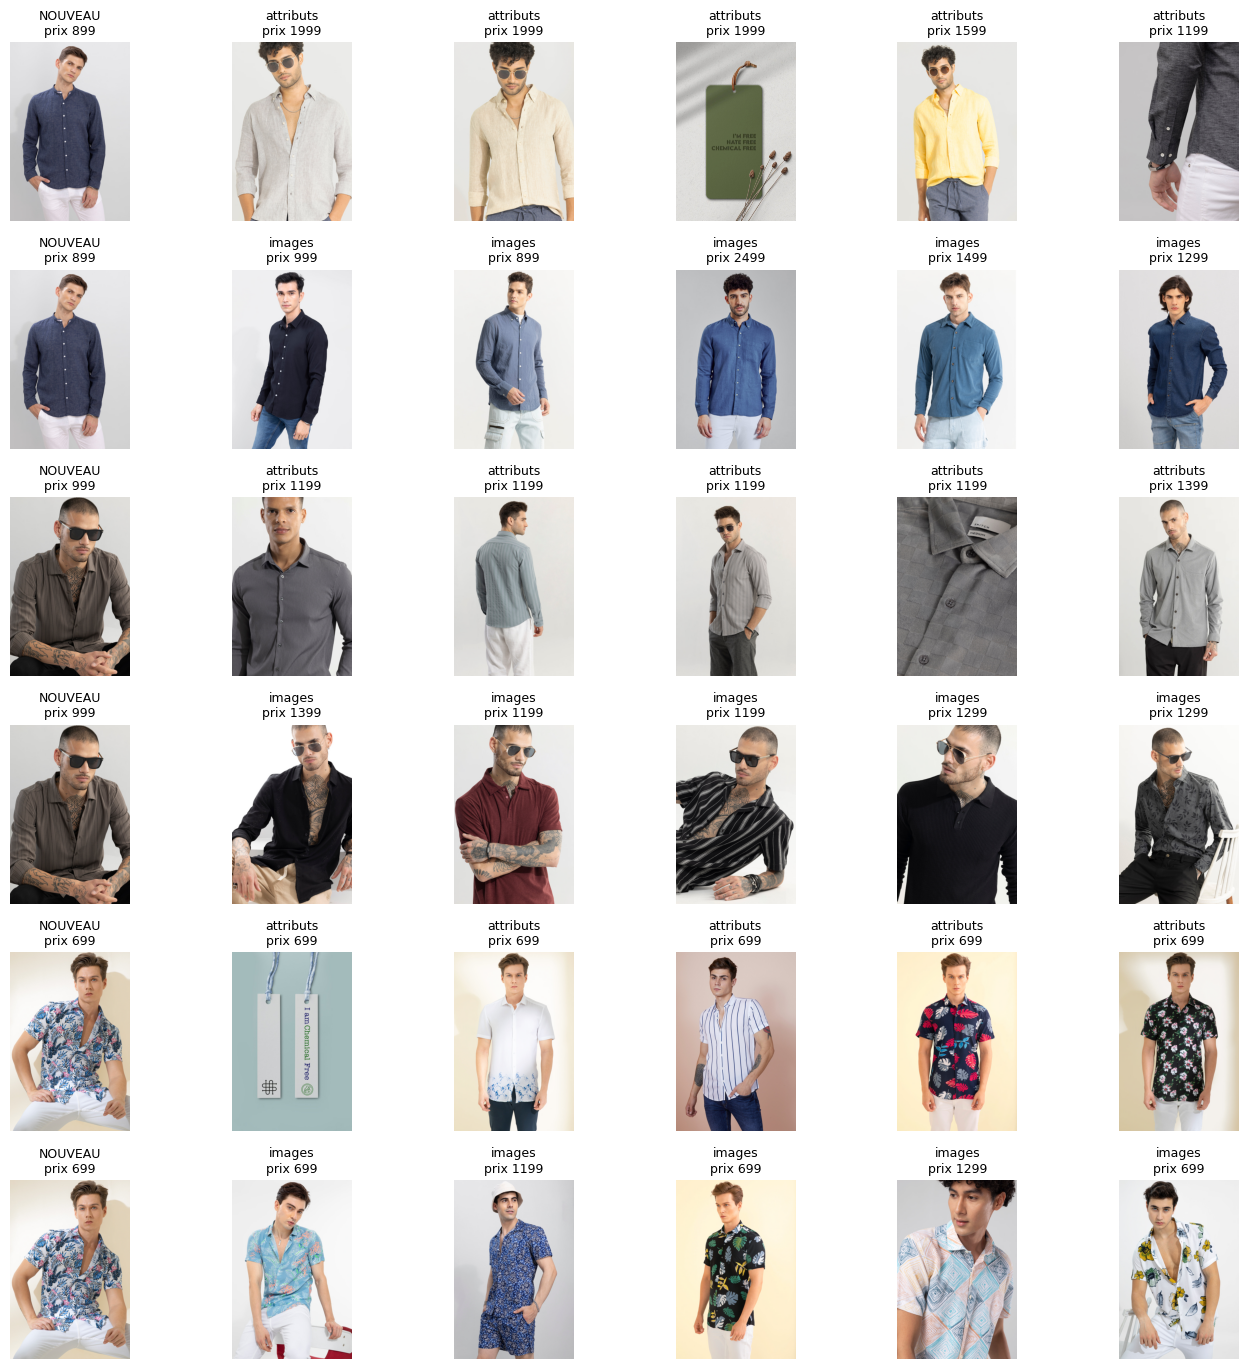

In [ ]:
import matplotlib.pyplot as plt, io
from PIL import Image

pf = knn_predict(S_attr_f, 5)                               # modèle retenu
pm = knn_predict(0.75 * S_attr_f + 0.25 * S_img, 5)         # variante multimodale
ape = lambda p: np.abs(p - yte) / yte

# 1) Erreurs par type (types avec >= 30 lignes de test)
rep = pd.DataFrame({"type": types[te],
                    "Moy. par type": ape(pred), "Attributs": ape(pf), "Attr.+images": ape(pm)})
n = rep.groupby("type").size().rename("n_test")
tab = (rep.groupby("type")[["Moy. par type", "Attributs", "Attr.+images"]].mean() * 100).round(1).join(n)
print("MAPE (%) par type, n_test >= 30 :")
print(tab[tab["n_test"] >= 30].sort_values("n_test", ascending=False).to_string())

# 2) Les 10 pires erreurs du modèle retenu
w = pd.DataFrame({"nom": df["Product Name"].values[te], "type": types[te],
                  "prix": yte, "prédit": pf.round(0), "erreur_%": (100 * ape(pf)).round(1)})
print("\n10 pires erreurs :")
print(w.sort_values("erreur_%", ascending=False).head(10).to_string(index=False))

# 3) Exemples visuels : requête + 5 voisins (attributs) + 5 voisins (images seules)
def img(i): return Image.open(io.BytesIO(ds[int(i)]["image_bytes"])).convert("RGB")
def top5(S_row): return np.argsort(-S_row)[:5]

rng = np.random.default_rng(0)
worst = int(np.argmax(ape(pf)))
queries = [worst] + list(rng.choice(len(te), 2, replace=False))   # 1 pire cas + 2 au hasard
fig, axes = plt.subplots(2 * len(queries), 6, figsize=(14, 4.6 * len(queries)))
for r, q in enumerate(queries):
    for row, (S, label) in enumerate(((S_attr_f, "attributs"), (S_img, "images"))):
        ax_row = axes[2 * r + row]
        ax_row[0].imshow(img(te[q])); ax_row[0].set_title(f"NOUVEAU\nprix {yte[q]:.0f}", fontsize=9)
        for c, j in enumerate(top5(S[q]), start=1):
            ax_row[c].imshow(img(tr[j])); ax_row[c].set_title(f"{label}\nprix {ytr[j]:.0f}", fontsize=9)
        for a in ax_row: a.axis("off")
plt.tight_layout()
plt.savefig(f"{PROJ}/artifacts/neighbors_examples.png", dpi=120)
plt.show()

In [ ]:
gte = df["group"].values[te]
ug = np.unique(gte)
idx_by_g = {g: np.where(gte == g)[0] for g in ug}
rng = np.random.default_rng(0)

def boot_ci(v, B=1000):
    out = []
    for _ in range(B):
        gs = rng.choice(ug, len(ug))
        ii = np.concatenate([idx_by_g[g] for g in gs])
        out.append(100 * v[ii].mean())
    return np.percentile(out, [2.5, 97.5]).round(2)

for name, p in [("Moyenne par type", pred), ("Attributs seuls k=5", pf), ("Attributs+images", pm)]:
    print(f"{name:20s} MAPE {100*ape(p).mean():.2f}  IC95% {boot_ci(ape(p))}")
print("Gain attributs vs moyenne par type (points de MAPE) :",
      round(100*(ape(pred)-ape(pf)).mean(), 2), boot_ci(ape(pred) - ape(pf)))
print("Gain attributs vs attributs+images (points) :",
      round(100*(ape(pm)-ape(pf)).mean(), 2), boot_ci(ape(pm) - ape(pf)))

Moyenne par type     MAPE 15.73  IC95% [14.52 17.  ]
Attributs seuls k=5  MAPE 7.36  IC95% [6.44 8.36]
Attributs+images     MAPE 7.66  IC95% [6.74 8.71]
Gain attributs vs moyenne par type (points de MAPE) : 8.37 [ 6.97 10.  ]
Gain attributs vs attributs+images (points) : 0.3 [-0.03  0.62]


In [ ]:
!pip -q install faiss-cpu
import faiss, time

d = E.shape[1]

# 1) Vérif : FAISS exact == numpy sur tes vraies données
idx_flat = faiss.IndexFlatIP(d); idx_flat.add(E[tr])
_, I = idx_flat.search(E[te], 5)
ref = np.argsort(-S_img, axis=1)[:, :5]
print("Même top-5 que numpy :", np.mean([set(a) == set(b) for a, b in zip(I, ref)]).round(4))

# 2) Base synthétique réaliste : 200k vecteurs = embeddings réels + bruit
rng = np.random.default_rng(0)
N = 200_000
Xb = E[rng.integers(0, len(E), N)] + 0.03 * rng.standard_normal((N, d)).astype("float32")
faiss.normalize_L2(Xb)
Q = Xb[rng.choice(N, 1000, replace=False)] + 0.01 * rng.standard_normal((1000, d)).astype("float32")
faiss.normalize_L2(Q)

def bench(name, index, train=False, setp=None):
    t = time.time()
    if train: index.train(Xb)
    index.add(Xb)
    build = time.time() - t
    if setp: setp(index)
    t = time.time(); _, I = index.search(Q, 10); batch = (time.time() - t) / len(Q) * 1000
    t = time.time()
    for q in Q[:200]: index.search(q[None], 10)
    single = (time.time() - t) / 200 * 1000
    size = len(faiss.serialize_index(index)) / 1e6
    return name, build, batch, single, size, I

truth = None
rows = []
for name, mk, tr_, sp_ in [
    ("Flat (exact)", lambda: faiss.IndexFlatIP(d), False, None),
    ("IVF1024 nprobe=16", lambda: faiss.IndexIVFFlat(faiss.IndexFlatIP(d), d, 1024, faiss.METRIC_INNER_PRODUCT), True,
        lambda i: setattr(i, "nprobe", 16)),
    ("HNSW M=32 ef=64", lambda: faiss.IndexHNSWFlat(d, 32, faiss.METRIC_INNER_PRODUCT), False,
        lambda i: setattr(i.hnsw, "efSearch", 64)),
    ("IVF1024-PQ64", lambda: faiss.IndexIVFPQ(faiss.IndexFlatIP(d), d, 1024, 64, 8, faiss.METRIC_INNER_PRODUCT), True,
        lambda i: setattr(i, "nprobe", 16)),
]:
    n_, b, bt, sg, sz, I = bench(name, mk(), tr_, sp_)
    if truth is None: truth = I
    rec = np.mean([len(set(a) & set(t)) / 10 for a, t in zip(I, truth)])
    rows.append(dict(index=n_, build_s=round(b, 1), ms_batch=round(bt, 3), ms_single=round(sg, 3),
                     MB_200k=round(sz, 0), recall10=round(rec, 3),
                     est_MB_1M=round(sz * 5, 0), est_ms_single_1M=round(sg * (5 if "Flat" in n_ else 1.5), 2)))
sc = pd.DataFrame(rows); print(sc.to_string(index=False))
sc.to_csv(f"{PROJ}/artifacts/scalability.csv", index=False)

# 3) Coût d'extraction des embeddings à 1 M d'articles (mesure : 33,5 ms/image de bout en bout, 1 T4)
sec = 1_000_000 * 0.03354
print(f"\n1 M images : {sec/3600:.1f} h sur 1 GPU T4 (décodage inclus), ~{sec/3600/8:.1f} h sur 8 workers en parallèle")

Même top-5 que numpy : 0.9337
            index  build_s  ms_batch  ms_single  MB_200k  recall10  est_MB_1M  est_ms_single_1M
     Flat (exact)      0.4     3.007     45.806    410.0     1.000     2048.0            229.03
IVF1024 nprobe=16     25.6     0.844      0.961    413.0     0.973     2067.0              1.44
  HNSW M=32 ef=64     98.5     0.612      0.622    464.0     0.982     2320.0              0.93
     IVF1024-PQ64     52.3     0.343      0.485     17.0     0.555       85.0              0.73

1 M images : 9.3 h sur 1 GPU T4 (décodage inclus), ~1.2 h sur 8 workers en parallèle


In [ ]:
sims_faiss, I = idx_flat.search(E[te], 5)
sims_np = -np.sort(-S_img, axis=1)[:, :5]
ok = np.isclose(sims_faiss, sims_np, atol=1e-3).all(axis=1)
print("Lignes où les similarités top-5 coïncident :", ok.mean().round(4))

Lignes où les similarités top-5 coïncident : 1.0


In [ ]:
sims_faiss, I = idx_flat.search(E[te], 5)
sims_np = -np.sort(-S_img, axis=1)[:, :5]
ok = np.isclose(sims_faiss, sims_np, atol=1e-3).all(axis=1)
print("Lignes où les similarités top-5 coïncident :", ok.mean().round(4))

Lignes où les similarités top-5 coïncident : 1.0
